# Search settings and number of chunks with the Sprint 3 answer prompt (E4, E3)
Gözde Nur Özdemir · ELIZA · Sprint 3 · KAN-245, KAN-177

**In short:**
- **Why:** in Sprint 2 the search and k = 8 were chosen by Recall@k only. Our target O2 (a) is measured on the answer, and the prompt changed (E2), so we check the search again (E4) and choose k by the answers (E3).
- **How:** the Sprint 2 grid (5 embedding models × 6 weights, weighted RRF, BM25 word lists); the word lists are also scored inside the hybrid search, with and without legal words (risk 2). Then every k that brings a missing gold provision in is answered with prompt v4 on the 30 `val` questions.
- **Result:** the Sprint 2 search stays (bge-m3, weight 0.8); keeping the legal words in BM25 raises Recall@8 from 0.61 to 0.62. k = 8 and k = 10 both give O2 (a) 20/21 = 95%; k = 10 gives no verdict sentence (k = 8: 2), so we choose **k = 10** (section 12).
- **W&B:** `fzohutgx` (search), `qx2rgzus` (ranks), `zxrho7cs`, `ih4q72rv`, `5ce22zts` (k = 8, 10, 16).

**How to run:** Colab → upload this file → *Runtime → Change runtime type → T4 GPU* → *Run all* (about 35 minutes). W&B asks for the key: choose 2, paste the key only into that box. The last cell downloads every result as one zip. The LLM jury is not asked again (`RUN_JURY = False`); its Sprint 2 words are used.

## 0. Setup (Colab only)

In [1]:
import os, subprocess, sys
if "google.colab" in sys.modules:
    REPO = "/content/ELIZA_DI502_ORGANIZATION"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/ELIZA-DI502/ELIZA_DI502_ORGANIZATION.git", REPO], check=True)
    subprocess.run("pip -q install sentence-transformers rank_bm25 wandb", shell=True, check=True)
    os.chdir(REPO + "/src")
sys.path.insert(0, "..")      # for rag.app.checks

## 1. Settings
Change only this cell. The Part 1 values are those of Sprint 2 (`src/embedding.ipynb`).

In [2]:
EVAL_SET = "../docs/eval/eval-set-v1.csv"       # the questions of Sprint 2, E1 and E2
SPLIT = "val"                                    # test is never used here
# Part 1: the search settings (as in Sprint 2)
RUN_JURY = False                                 # True = ask the LLM jury again (about 40 minutes more); False = use its words from config/rag.yaml
JURY = ["qwen3:14b", "phi4:14b", "gemma3:12b"]   # three model families, 12-14B (Sprint 2)
# the 5 models and 6 weights of Sprint 2 (src/embedding.ipynb): the grid that is searched; the best one is chosen by the code
EMBEDDING_MODELS = ["sentence-transformers/all-MiniLM-L6-v2", "BAAI/bge-small-en-v1.5", "BAAI/bge-base-en-v1.5",
                    "BAAI/bge-large-en-v1.5", "BAAI/bge-m3"]
DENSE_WEIGHTS = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]   # 0.5 = plain RRF, 1.0 = dense only
# K = 8 (retrieval.top_k) and K_MAX = 20 (retrieval.candidates) are read from config/rag.yaml in section 2
K_SHOW = [5, 8, 10, 12, 16]                      # Recall is also shown at these k (only shown, not used to choose)
LEGAL_WORDS = ["must", "only", "may", "except", "under", "first", "shall"]   # risk 2: words that can carry legal meaning (review of Sprint 2)
# Part 2: the number of chunks
PROMPT_REF = "b5140a0"                           # commit of prompt v4 (PR #110), fixed so the run can be repeated
NUM_CTX = 4096                                   # context window, as in E2 and src/answer_time.py
TIME_FACTOR = 1.5                                # rule 3, written before the run
LOG_TO_WANDB = True

## 2. The prompt, the chunks and the questions

In [3]:
import subprocess, time, statistics, hashlib, requests
subprocess.run(["git", "fetch", "-q", "origin"], check=False)     # also fetches the commit of prompt v4
COMMIT = subprocess.run(["git", "rev-parse", PROMPT_REF], capture_output=True, text=True, check=True).stdout.strip()
PROMPT_TEXT = subprocess.run(["git", "show", f"{COMMIT}:prompts/answer.yaml"], capture_output=True, text=True, check=True).stdout
PROMPT_ID = "local-" + hashlib.sha256(PROMPT_TEXT.encode()).hexdigest()[:12]   # fingerprint of the prompt text (prompt v4: local-b0177171c2f5)
print("Prompt", PROMPT_REF, "| commit", COMMIT[:7], "| fingerprint", PROMPT_ID)

Prompt b5140a0 | commit b5140a0 | fingerprint local-b0177171c2f5


In [4]:
import csv, json, re
from collections import Counter
import numpy as np, pandas as pd, yaml, torch
from rank_bm25 import BM25Okapi
pd.set_option("display.max_colwidth", 200)
np.random.seed(42)

CONFIG = yaml.safe_load(open("../config/rag.yaml"))
R, A = CONFIG["retrieval"], CONFIG["answer"]
K = R["top_k"]                                   # 8: the number of chunks of Sprint 2 (D14); Part 1 chooses at this k (Recall@8)
K_MAX = R["candidates"]                          # 20: each search list gives 20 candidates, so ranks are looked at up to 20
PROMPT = yaml.safe_load(PROMPT_TEXT)
chunks = [json.loads(line) for line in open("../data/chunks.jsonl", encoding="utf-8")]
by_chunk = {c["chunk_id"]: c for c in chunks}
ref_of = {c["chunk_id"]: c["ref"] for c in chunks}
base = lambda cid: cid.split("#")[0]                    # ART13-3#2 is the second part of the provision ART13-3
questions = [r for r in csv.DictReader(open(EVAL_SET, encoding="utf-8-sig")) if r["split"] == SPLIT]
by_id = {q["id"]: q for q in questions}
dev = [q for q in questions if q["gold_ids"].strip()]   # the val questions with gold provisions, as in Sprint 2
words = lambda text: re.findall(r"[a-z0-9]+", text.lower())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def score(search, k=K):
    """Recall@k, capped Recall@k, MRR and Precision@k over the val questions, on gold provision IDs (as in Sprint 2)."""
    recall, capped, rr, precision = [], [], [], []
    for q in dev:
        gold = set(q["gold_ids"].split(";"))
        found = [base(c) for c in search(q["question"])[:k]]
        hits = len(gold & set(found))
        recall.append(hits / len(gold)); capped.append(hits / min(k, len(gold)))
        rr.append(next((1 / n for n, p in enumerate(found, 1) if p in gold), 0))
        precision.append(np.mean([p in gold for p in found]))
    return {f"Recall@{k}": round(np.mean(recall), 2), f"Capped recall@{k}": round(np.mean(capped), 2),
            "MRR": round(np.mean(rr), 2), f"Precision@{k}": round(np.mean(precision), 2)}

CODE_COMMIT = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
SOURCE = {"celex": CONFIG["chunking"]["celex"], "version_date": CONFIG["chunking"]["version_date"]}
print(len(chunks), "chunks;", len(questions), SPLIT, "questions,", len(dev), "with gold provisions | code commit", CODE_COMMIT[:7], "| device", DEVICE)

105 chunks; 30 val questions, 29 with gold provisions | code commit 033de8e | device cuda


# Part 1 · The search settings (E4)
The Sprint 2 steps, run again. No answer model here. Scores are a little higher than in Sprint 2 because 29 questions have gold provisions now (27 before).

## 3. The most frequent words
The 20 words in the most chunks; the jury labels them.

In [5]:
bm25_all = BM25Okapi([words(c["embed_text"]) for c in chunks])
in_q = Counter(w for q in questions for w in set(words(q["question"])))
in_c = Counter(w for c in chunks for w in set(words(c["embed_text"])))
weights = pd.DataFrame([{"word": w, "% of chunks": round(100 * n / len(chunks)), "BM25 weight (IDF)": round(bm25_all.idf[w], 2),
                         "% of questions": round(100 * in_q[w] / len(questions))} for w, n in in_c.items()])
candidates = weights.sort_values("% of chunks", ascending=False).head(20).reset_index(drop=True)
candidates

,word,% of chunks,BM25 weight (IDF),% of questions
0,article,100,0.89,0
1,the,91,0.89,83
2,of,89,0.89,13
3,ai,86,0.89,63
4,in,76,0.89,23
5,to,74,0.89,53
6,shall,70,0.89,0
7,and,66,0.89,63
8,risk,65,0.89,53
9,paragraph,64,0.89,0


**Comment:** the same words as in Sprint 2. Some are also in many questions (*ai*, *risk*, *high*), so we cannot drop a word just because it is frequent.

## 4. The LLM jury
Three models (`qwen3:14b`, `phi4:14b`, `gemma3:12b`) vote IGNORE or KEEP for each word; the majority wins.

In [6]:
JURY_PROMPT = """This word appears in many EU AI Act provisions. Examples:
{examples}
Should a keyword search IGNORE it (common wording that does not help to find the right provision)
or KEEP it (a question can depend on it)? If in doubt, KEEP.
Answer in one line: IGNORE or KEEP, then a reason of at most 12 words.
WORD: {word}"""

def ollama_up():
    """Installs (Colab) and starts Ollama 0.40.15 if it is not running."""
    import requests, time
    url = CONFIG["judge"]["url"].replace("/api/chat", "/api/tags")
    try:
        requests.get(url, timeout=5); return True
    except Exception:
        pass
    if subprocess.run("which ollama", shell=True, capture_output=True).returncode or not os.path.exists("/usr/local/lib/ollama/llama-server"):
        subprocess.run("pkill -x ollama; rm -rf /usr/local/lib/ollama; apt-get -qq update > /dev/null; apt-get -qq install -y zstd > /dev/null; "
                       "curl -fsSL https://ollama.com/install.sh | OLLAMA_VERSION=0.40.15 sh > /dev/null", shell=True, check=True)
    subprocess.Popen(["ollama", "serve"], stdout=open("ollama.log", "w"), stderr=subprocess.STDOUT)
    for _ in range(30):
        time.sleep(2)
        try:
            requests.get(url, timeout=5); return True
        except Exception:
            pass
    return False

if RUN_JURY:
    import requests
    print("Ollama running:", ollama_up())
    for m in JURY:
        print("Downloading", m); subprocess.run(["ollama", "pull", m], check=True, capture_output=True)
    def ask_judge(model, prompt):
        body = {"model": model, "stream": False, "messages": [{"role": "user", "content": prompt + (" /no_think" if model.startswith("qwen3") else "")}],
                "options": {"temperature": CONFIG["judge"]["temperature"], "num_predict": CONFIG["judge"]["num_predict"]}}
        if model.startswith("qwen3"):
            body["think"] = False
        text = requests.post(CONFIG["judge"]["url"], json=body, timeout=300).json()["message"]["content"]
        return text.split("</think>")[-1].strip()
    label = lambda text: (re.match(r"\W*(IGNORE|KEEP)\b", text.upper()) or [None, "UNCLEAR"])[1]
    examples = lambda w: "\n".join(f'- {c["ref"]}: {c["text"][:150]}...' for c in chunks if w in words(c["text"]))
    jury = candidates[["word", "% of questions"]].copy()
    for model in JURY:
        jury[model] = [label(ask_judge(model, JURY_PROMPT.format(examples="\n".join(examples(w).splitlines()[:3]), word=w))) for w in jury["word"]]
        print(model, "done")
    jury["majority"] = np.where((jury[JURY] == "IGNORE").sum(axis=1) >= 2, "IGNORE", "KEEP")
    JURY_IGNORE = set(jury.loc[jury["majority"] == "IGNORE", "word"])
    for m in JURY:
        subprocess.run(["ollama", "rm", m], capture_output=True)          # free the disk for the answer model
else:
    JURY_IGNORE = set(CONFIG["bm25"]["jury_words"])
    jury = pd.DataFrame({"word": sorted(JURY_IGNORE), "majority": "IGNORE (Sprint 2, config/rag.yaml)"})
print("Jury words:", sorted(JURY_IGNORE), "| same as Sprint 2:", JURY_IGNORE == set(CONFIG["bm25"]["jury_words"]))
jury

Jury words: ['a', 'and', 'for', 'of', 'paragraph', 'shall', 'that', 'the', 'this', 'to'] | same as Sprint 2: True


,word,majority
0,a,"IGNORE (Sprint 2, config/rag.yaml)"
1,and,"IGNORE (Sprint 2, config/rag.yaml)"
2,for,"IGNORE (Sprint 2, config/rag.yaml)"
3,of,"IGNORE (Sprint 2, config/rag.yaml)"
4,paragraph,"IGNORE (Sprint 2, config/rag.yaml)"
5,shall,"IGNORE (Sprint 2, config/rag.yaml)"
6,that,"IGNORE (Sprint 2, config/rag.yaml)"
7,the,"IGNORE (Sprint 2, config/rag.yaml)"
8,this,"IGNORE (Sprint 2, config/rag.yaml)"
9,to,"IGNORE (Sprint 2, config/rag.yaml)"


**Comment:** the jury's Sprint 2 words are used; asking again would give the same list.

## 5. Which words should BM25 not see?
Six word lists on BM25 alone, as in Sprint 2. A list wins only if it is better on Recall@8 or MRR and worse on neither; a tie keeps Sprint 2.

In [7]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
STOPWORDS = set(ENGLISH_STOP_WORDS) - {"not", "no", "nor"}
FREQUENT = set(weights.loc[weights["% of chunks"] >= 50, "word"]) - {"not", "no", "nor"}
REMOVE = {"none": set(), "jury": JURY_IGNORE, "stopwords": STOPWORDS, "stopwords + jury": STOPWORDS | JURY_IGNORE,
          "frequent words": FREQUENT, "stopwords + frequent words": STOPWORDS | FREQUENT}

def bm25_search(remove):
    index = BM25Okapi([[w for w in words(c["embed_text"]) if w not in remove] for c in chunks])
    return lambda q: [chunks[n]["chunk_id"] for n in np.argsort(-index.get_scores([w for w in words(q) if w not in remove]))]

bm25_table = pd.DataFrame([{"word list": v, **score(bm25_search(r))} for v, r in REMOVE.items()]).set_index("word list")
rule = [f"Recall@{K}", "MRR"]
better = lambda v: (bm25_table.loc[v, rule] >= bm25_table.loc["none", rule]).all() and (bm25_table.loc[v, rule] > bm25_table.loc["none", rule]).any()
winners = [v for v in REMOVE if v != "none" and better(v)]
top = max((tuple(bm25_table.loc[v, rule]) for v in winners), default=None)
tied = [v for v in winners if tuple(bm25_table.loc[v, rule]) == top]
BM25_LIST = (CONFIG["bm25"]["remove"] if CONFIG["bm25"]["remove"] in tied else tied[0]) if tied else "none"   # a tie keeps the Sprint 2 setting
print("BM25 word list:", BM25_LIST, "| Sprint 2:", CONFIG["bm25"]["remove"])
bm25_table

BM25 word list: stopwords + jury | Sprint 2: stopwords + jury


,Recall@8,Capped recall@8,MRR,Precision@8
word list,,,,
none,0.37,0.39,0.43,0.13
jury,0.41,0.42,0.47,0.14
stopwords,0.47,0.48,0.52,0.15
stopwords + jury,0.47,0.48,0.52,0.15
frequent words,0.39,0.40,0.42,0.13
stopwords + frequent words,0.39,0.40,0.44,0.11


**Comment:** removing stopwords helps BM25 most (Recall@8 0.37 → 0.47). The jury's words add nothing more, so the Sprint 2 list stays.

## 6. Which embedding model, and how much BM25?
5 models × 6 dense weights, joined with BM25 by weighted RRF. Highest Recall@8 wins, then MRR.

In [8]:
from sentence_transformers import SentenceTransformer
INSTRUCTION = CONFIG["embedding"]["query_instruction"]
bm25_chosen = bm25_search(REMOVE[BM25_LIST])
keyword = {q["question"]: bm25_chosen(q["question"])[:R["candidates"]] for q in questions}
short_name = lambda name: name.split("/")[1].replace("-en-v1.5", "")
encoders = {}

def dense_lists(name, strip=None):
    """The 20 closest chunks of every val question with one embedding model (strip: words removed before embedding)."""
    if name not in encoders:
        encoders[name] = SentenceTransformer(name, device=DEVICE)
    model = encoders[name]
    prep = (lambda t: " ".join(w for w in words(t) if w not in strip)) if strip else (lambda t: t)
    vectors = model.encode([prep(c["embed_text"]) for c in chunks], normalize_embeddings=True)
    instruction = INSTRUCTION if name.endswith("en-v1.5") else ""     # the bge v1.5 models expect the query instruction
    return {q["question"]: [chunks[n]["chunk_id"] for n in np.argsort(-(vectors @ model.encode([instruction + prep(q["question"])], normalize_embeddings=True)[0]))][:R["candidates"]]
            for q in questions}

def weighted(dense, w, kw=None):
    """Weighted RRF of the dense list and the BM25 list (kw: another BM25 list, for risk 2)."""
    kw = kw or keyword
    def search(question):
        fused = Counter()
        for weight, lst in ((w, dense[question]), (1 - w, kw[question])):
            for rank, cid in enumerate(lst, 1):
                fused[cid] += weight / (R["rrf_k"] + rank)
        return [cid for cid, _ in fused.most_common()]
    return search

lists, rows = {}, [{"model": "BM25 only", "dense weight": 0.0, **score(lambda q: keyword[q])}]
for name in EMBEDDING_MODELS:
    lists[name] = dense_lists(name)
    rows += [{"model": short_name(name), "dense weight": w, **score(weighted(lists[name], w))} for w in DENSE_WEIGHTS]
    print("scored", short_name(name))
searches = pd.DataFrame(rows)
ranked_settings = searches.iloc[1:].sort_values([f"Recall@{K}", "MRR"], ascending=False)
top = ranked_settings.iloc[0][[f"Recall@{K}", "MRR"]].tolist()
tied = ranked_settings[(ranked_settings[f"Recall@{K}"] == top[0]) & (ranked_settings["MRR"] == top[1])]
sprint2 = tied[(tied["model"] == short_name(CONFIG["embedding"]["model"])) & (tied["dense weight"] == R["dense_weight"])]
best = (sprint2 if len(sprint2) else tied).iloc[0]                    # a tie keeps the Sprint 2 setting
BEST_MODEL = next(n for n in EMBEDDING_MODELS if short_name(n) == best["model"])
BEST_WEIGHT = float(best["dense weight"])
print(f"Winner at k = {K}: {short_name(BEST_MODEL)} with dense weight {BEST_WEIGHT} | Sprint 2: {short_name(CONFIG['embedding']['model'])} with {R['dense_weight']}")
display(searches.iloc[1:].pivot(index="model", columns="dense weight", values=f"Recall@{K}"))
at_k = pd.DataFrame([{"model": short_name(n), "dense weight": w, **{f"Recall@{k}": score(weighted(lists[n], w), k)[f"Recall@{k}"] for k in K_SHOW}}
                     for n in EMBEDDING_MODELS for w in DENSE_WEIGHTS])
winner_at = {k: at_k.sort_values(f"Recall@{k}", ascending=False).iloc[0][["model", "dense weight"]].tolist() for k in K_SHOW}
print("Best model and weight by Recall@k:", winner_at)
at_k.sort_values(f"Recall@{K}", ascending=False).head(10)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (67 outputs left out)

scored bge-m3
Winner at k = 8: bge-m3 with dense weight 0.8 | Sprint 2: bge-m3 with 0.8


dense weight,0.5,0.6,0.7,0.8,0.9,1.0
model,,,,,,
all-MiniLM-L6-v2,0.47,0.47,0.47,0.44,0.45,0.32
bge-base,0.51,0.52,0.52,0.51,0.57,0.53
bge-large,0.53,0.52,0.53,0.54,0.59,0.53
bge-m3,0.59,0.60,0.61,0.61,0.58,0.55
bge-small,0.54,0.53,0.53,0.53,0.50,0.48


Best model and weight by Recall@k: {5: ['bge-m3', np.float64(0.9)], 8: ['bge-m3', np.float64(0.8)], 10: ['bge-m3', np.float64(0.5)], 12: ['bge-m3', np.float64(0.5)], 16: ['bge-base', np.float64(0.6)]}


,model,dense weight,Recall@5,Recall@8,Recall@10,Recall@12,Recall@16
27,bge-m3,0.8,0.47,0.61,0.64,0.65,0.69
26,bge-m3,0.7,0.47,0.61,0.64,0.65,0.69
25,bge-m3,0.6,0.47,0.60,0.64,0.65,0.69
22,bge-large,0.9,0.52,0.59,0.62,0.65,0.68
24,bge-m3,0.5,0.47,0.59,0.66,0.68,0.69
28,bge-m3,0.9,0.53,0.58,0.61,0.64,0.69
16,bge-base,0.9,0.43,0.57,0.59,0.66,0.70
29,bge-m3,1.0,0.49,0.55,0.59,0.60,0.66
6,bge-small,0.5,0.45,0.54,0.55,0.59,0.65
21,bge-large,0.8,0.47,0.54,0.62,0.64,0.68


**Comment:** bge-m3 with weight 0.8 is still best (0.61). bge-m3 alone gets 0.55, so a little BM25 still helps.

## 6b. Remove words before embedding?
The same lists, taken out before bge-m3 reads the text.

In [9]:
before = {"full text": lists[BEST_MODEL]}
before.update({v: dense_lists(BEST_MODEL, REMOVE[v]) for v in ["jury", "stopwords", "stopwords + jury", "frequent words", "stopwords + frequent words"]})
before_table = pd.DataFrame([{"before embedding": v, **score(weighted(l, BEST_WEIGHT))} for v, l in before.items()]).set_index("before embedding")
better_than_full = [v for v in before_table.index[1:] if tuple(before_table.loc[v, rule]) > tuple(before_table.loc["full text", rule])]
REMOVE_BEFORE_EMBEDDING = max(better_than_full, key=lambda v: tuple(before_table.loc[v, rule])) if better_than_full else "none"
print("Words removed before embedding:", REMOVE_BEFORE_EMBEDDING, "| Sprint 2:", CONFIG["embedding"]["remove_before_embedding"])
before_table

Words removed before embedding: none | Sprint 2: none


,Recall@8,Capped recall@8,MRR,Precision@8
before embedding,,,,
full text,0.61,0.63,0.62,0.19
jury,0.55,0.57,0.65,0.18
stopwords,0.49,0.50,0.55,0.16
stopwords + jury,0.50,0.53,0.50,0.18
frequent words,0.49,0.50,0.60,0.15
stopwords + frequent words,0.45,0.47,0.52,0.15


**Comment:** the full text is best, as in Sprint 2. The model needs whole sentences.

## 6c. Word lists inside the hybrid search, and risk 2
The product uses the hybrid search, so the word lists are scored inside it, with and without the legal words (*must, only, may, except, under, first, shall*). The Sprint 2 list changes only if another version is better; a tie keeps the one closest to Sprint 2.

In [10]:
base_lists = before[REMOVE_BEFORE_EMBEDDING] if REMOVE_BEFORE_EMBEDDING != "none" else lists[BEST_MODEL]
LEGAL = set(LEGAL_WORDS)
variants = {}
for v, out in REMOVE.items():
    variants[(v, False)] = out
    if out & LEGAL:
        variants[(v, True)] = out - LEGAL
kw_of, rows = {}, []
for (v, keep), out in variants.items():
    f = bm25_search(out)
    kw_of[(v, keep)] = {q["question"]: f(q["question"])[:R["candidates"]] for q in questions}
    rows.append({"BM25 word list": v, "legal words": "kept" if keep else ("removed" if out & LEGAL else "not removed"),
                 **score(weighted(base_lists, BEST_WEIGHT, kw_of[(v, keep)]))})
hybrid_words = pd.DataFrame(rows)
key = lambda r: (r[f"Recall@{K}"], r["MRR"])
current = hybrid_words[(hybrid_words["BM25 word list"] == BM25_LIST) & (hybrid_words["legal words"] == "removed")].iloc[0]
better = hybrid_words[[(r[f"Recall@{K}"] >= current[f"Recall@{K}"] and r["MRR"] >= current["MRR"] and key(r) != key(current)) for _, r in hybrid_words.iterrows()]]
if len(better):
    top = better[[key(r) == max(key(r2) for _, r2 in better.iterrows()) for _, r in better.iterrows()]]
    same_list = top[top["BM25 word list"] == BM25_LIST]          # a tie keeps the version closest to Sprint 2 (one change at a time)
    best_row = (same_list if len(same_list) else top).iloc[0]
    BM25_LIST, KEEP_LEGAL = best_row["BM25 word list"], best_row["legal words"] == "kept"
else:
    KEEP_LEGAL = False
uses = Counter(w for q in questions for w in set(words(q["question"])) if w in LEGAL)
print("Legal words in the val questions:", dict(uses) or "none")
print("BM25 word list in the hybrid search:", BM25_LIST, "| legal words kept:", KEEP_LEGAL)
hybrid_words.sort_values([f"Recall@{K}", "MRR"], ascending=False)

Legal words in the val questions: {'must': 1, 'only': 6, 'under': 2}
BM25 word list in the hybrid search: stopwords + jury | legal words kept: True


,BM25 word list,legal words,Recall@8,Capped recall@8,MRR,Precision@8
4,stopwords,kept,0.62,0.64,0.62,0.19
6,stopwords + jury,kept,0.62,0.64,0.62,0.19
3,stopwords,removed,0.61,0.63,0.62,0.19
5,stopwords + jury,removed,0.61,0.63,0.62,0.19
9,stopwords + frequent words,removed,0.57,0.59,0.59,0.19
10,stopwords + frequent words,kept,0.56,0.58,0.58,0.18
1,jury,removed,0.55,0.57,0.66,0.18
2,jury,kept,0.55,0.57,0.66,0.18
8,frequent words,kept,0.54,0.56,0.63,0.17
7,frequent words,removed,0.54,0.56,0.61,0.17


**Comment:** removing stopwords is right in the hybrid search too (0.48 without it). Keeping the legal words finds one more gold provision (0.61 → 0.62), so they stay. Only 9 questions use these words, so the gain is small.

## The chosen search
Part 1 against `config/rag.yaml`.

In [11]:
chosen = pd.DataFrame([
    {"setting": "embedding.model", "Sprint 2 (config/rag.yaml)": CONFIG["embedding"]["model"], "now": BEST_MODEL},
    {"setting": "retrieval.dense_weight", "Sprint 2 (config/rag.yaml)": R["dense_weight"], "now": BEST_WEIGHT},
    {"setting": "bm25.remove", "Sprint 2 (config/rag.yaml)": CONFIG["bm25"]["remove"], "now": BM25_LIST},
    {"setting": "embedding.remove_before_embedding", "Sprint 2 (config/rag.yaml)": CONFIG["embedding"]["remove_before_embedding"], "now": REMOVE_BEFORE_EMBEDDING},
    {"setting": "legal words kept in BM25 (risk 2)", "Sprint 2 (config/rag.yaml)": False, "now": KEEP_LEGAL},
]).set_index("setting")
chosen["same"] = [str(a) == str(b) for a, b in zip(chosen.iloc[:, 0], chosen.iloc[:, 1])]
SEARCH_LISTS = before[REMOVE_BEFORE_EMBEDDING] if REMOVE_BEFORE_EMBEDDING != "none" else lists[BEST_MODEL]
chosen_search = weighted(SEARCH_LISTS, BEST_WEIGHT, kw_of[(BM25_LIST, KEEP_LEGAL)])
ranked = lambda question: [by_chunk[cid] for cid in chosen_search(question)]
for name in [n for n in encoders if n != BEST_MODEL]:      # free the GPU for the answer model
    del encoders[name]
torch.cuda.empty_cache() if DEVICE == "cuda" else None
search = lambda question, k: ranked(question)[:k]
print("Chosen search:", score(chosen_search), "| the same as Sprint 2:", bool(chosen["same"].all()))
chosen

Chosen search: {'Recall@8': np.float64(0.62), 'Capped recall@8': np.float64(0.64), 'MRR': np.float64(0.62), 'Precision@8': np.float64(0.19)} | the same as Sprint 2: False


,Sprint 2 (config/rag.yaml),now,same
setting,,,
embedding.model,BAAI/bge-m3,BAAI/bge-m3,True
retrieval.dense_weight,0.8,0.8,True
bm25.remove,stopwords + jury,stopwords + jury,True
embedding.remove_before_embedding,none,none,True
legal words kept in BM25 (risk 2),False,True,False


**Comment:** the Sprint 2 search stays. The only change: the legal words are kept in BM25.

# Part 2 · The number of chunks (E3)
First the search alone, then the answers.

## 7. Step 1: where are the gold provisions?
Recall@k for k = 5 to 20, with the chosen search.

In [12]:
scored = [q for q in questions if q["gold_ids"].strip()]
order = {q["id"]: [base(c["chunk_id"]) for c in ranked(q["question"])] for q in scored}
gold_of = {q["id"]: q["gold_ids"].split(";") for q in scored}
rank_of = lambda i, g: order[i].index(g) + 1 if g in order[i] else None
first_rank = {i: min([r for r in (rank_of(i, g) for g in gold_of[i]) if r] or [None]) if any(rank_of(i, g) for g in gold_of[i]) else None
              for i in order}

K_VALUES = [5, 8, 10, 12, 14, 16, 18, 20]
recall = pd.DataFrame({"k": K_VALUES,
    "Recall@k": [round(np.mean([len(set(gold_of[i]) & set(order[i][:k])) / len(gold_of[i]) for i in order]), 2) for k in K_VALUES],
    "questions with a gold provision in the first k": [f"{sum(1 for i in order if first_rank[i] and first_rank[i] <= k)}/{len(order)}" for k in K_VALUES]})
print("MRR:", round(np.mean([1 / first_rank[i] if first_rank[i] else 0 for i in order]), 2))
recall

MRR: 0.62


,k,Recall@k,questions with a gold provision in the first k
0,5,0.46,23/29
1,8,0.62,26/29
2,10,0.63,27/29
3,12,0.65,27/29
4,14,0.66,27/29
5,16,0.69,28/29
6,18,0.70,28/29
7,20,0.71,28/29


**Comment:** 26 of 29 questions have a gold provision in the first 8. After 8, Recall grows slowly (0.62 → 0.71 at 20).

**Rank of each gold provision** for the questions more chunks could change (– = not in the first 20).

In [13]:
rows = []
for q in scored:
    i = q["id"]
    ranks = {g: rank_of(i, g) for g in gold_of[i]}
    later = [g for g, r in ranks.items() if r and 8 < r <= K_MAX]
    if (first_rank[i] or 99) > 8 or later:
        rows.append({"id": i, "type": q["type"], "expected": q["expected_behaviour"],
                     "first gold rank": first_rank[i] or "–",
                     "search miss at k = 8": (first_rank[i] or 99) > 8,
                     "gold ranks": ", ".join(f"{g} {r or '–'}" for g, r in ranks.items())})
ranks_table = pd.DataFrame(rows)
ranks_table

,id,type,expected,first gold rank,search miss at k = 8,gold ranks
0,A-01,multi-provision,answer,1,False,"ART10-2 1, ART10-3 4, ART10-4 23, ART12-1 17, ART12-2 11"
1,A-06,condition / exception,answer,1,False,"ART6-3-1 1, ART6-3-d 15, ART6-3-3 8"
2,B-01,condition / exception,answer,3,False,"ART6-2 3, ART6-3-1 15, ART6-3-a –, ART6-3-3 5"
3,B-05,multi-provision,answer,2,False,"ART8-1 2, ART9-1 –, ART10-1 –, ART11-1 27, ART12-1 20, ART13-1 –, ART13-2 –, ART14-1 17, ART15-1 –"
4,B-06,direct lookup,answer,9,True,"ART113-3-c-i 9, ANX3-3-b –, ART113-2 –"
5,B-S4,legal decision,redirect,1,False,"ART6-3-1 1, ART6-3-b –, ART6-4 11, ART49-2 –"
6,C-05,boundary case,answer,–,True,"ART5-1-f –, ART113-3-a –"
7,D-05,multi-provision,answer,1,False,"ANX3-3-b 3, ANX3-3-d 1, ART6-2 26, ART8-1 35, ART9-1 –, ART10-1 –, ART11-1 –, ART12-1 12, ART13-1 –, ART14-1 19, ART15-1 –"
8,D-08,multi-provision,answer,1,False,"ANX3-3-d 1, ART6-2 29, ART6-3-1 –, ART6-3-3 27, ART8-1 –, ART9-1 –, ART10-1 –, ART11-1 22, ART12-1 14, ART13-1 –, ART14-1 5, ART15-1 –, ART16-a 26, ART16-b 36, ART16-c –, ART16-d –, ART16-e 30, AR..."
9,D-09,multi-provision,answer,3,False,"ART8-1 –, ART9-1 19, ART10-1 –, ART11-1 10, ART12-1 –, ART13-1 29, ART14-1 –, ART15-1 –, ART16-a 17, ART16-b 11, ART16-c 9, ART16-d 18, ART16-e 20, ART16-f 3, ART16-g –, ART16-h 8, ART16-i –, ART1..."


**Comment:** three questions miss in the first 8: B-06 (rank 9), D-10 (rank 15) and C-05 (not in 20). Provisions around rank 15–20 need a better search, not a few more chunks.

**All missed gold provisions.** Recall@8 = 0.62 means many gold provisions are not in the first 8. Where are they?

In [ ]:
# every gold provision of the 29 questions: where does the chosen search rank it?
BUCKETS = ["1-8", "9-10", "11-16", "17-20", "not in the first 20"]
where = lambda r: BUCKETS[0] if r and r <= 8 else BUCKETS[1] if r and r <= 10 else BUCKETS[2] if r and r <= 16 else BUCKETS[3] if r and r <= 20 else BUCKETS[4]
all_gold = pd.DataFrame([{"id": i, "gold": g, "where": where(rank_of(i, g))} for i in order for g in gold_of[i]])
for b in BUCKETS:
    print(f"{b:<22}{(all_gold['where'] == b).sum()}")
print("total", len(all_gold))
print("Missed in the first 8, per question:", all_gold[all_gold["where"] != BUCKETS[0]].groupby("id").size().sort_values(ascending=False).head(4).to_dict())

1-8                   45
9-10                  3
11-16                 11
17-20                 8
not in the first 20   65
total 132
Missed in the first 8, per question: {'D-08': 23, 'D-09': 18, 'D-05': 9, 'B-05': 8}


**Comment:** of 132 gold provisions, 45 are in the first 8 and 65 are not even in the first 20. 58 of the 87 misses come from four questions that ask for a whole set of requirements (D-08, D-09, D-05, B-05). A few more chunks cannot bring these in (k = 10 adds 3, k = 16 adds 14); they need a better search, for example splitting the question into smaller ones (Sprint 4). We read the misses: no gold answer is wrong. Only 9 misses are search misses (C-05, D-10, B-06); the rest are whole sets of requirements or supporting provisions in the gold answers (E4 card).

**Recall@8 and MRR, question by question.** The questions that lose Recall (gold provisions not in the first 8) or MRR (the first gold provision not at rank 1).

In [ ]:
# Recall@8 and the rank of the first gold provision, question by question
per_q = pd.DataFrame([{"id": i, "type": by_id[i]["type"], "gold provisions": len(gold_of[i]),
                       f"Recall@{K}": round(len(set(gold_of[i]) & set(order[i][:K])) / len(gold_of[i]), 2),
                       "first gold rank": first_rank[i] or "–", "RR": 1 / first_rank[i] if first_rank[i] else 0} for i in order])
low = per_q[(per_q[f"Recall@{K}"] < 1) | (per_q["first gold rank"] != 1)].sort_values([f"Recall@{K}", "RR"], kind="stable")
print(f"Recall@{K} {per_q[f'Recall@{K}'].mean():.2f}, MRR {per_q['RR'].mean():.2f}; first gold provision at rank 1 for {(per_q['first gold rank'] == 1).sum()} of {len(per_q)} questions")
print(low.drop(columns="RR").to_string(index=False))

Recall@8 0.62, MRR 0.62; first gold provision at rank 1 for 14 of 29 questions
  id                  type  gold provisions  Recall@8 first gold rank
C-05         boundary case                2      0.00               –
D-10             follow-up                4      0.00              15
B-06         direct lookup                3      0.00               9
D-09       multi-provision               20      0.10               3
B-05       multi-provision                9      0.11               2
D-08       multi-provision               26      0.12               1
D-05       multi-provision               11      0.18               1
B-S4        legal decision                4      0.25               1
A-05         direct lookup                3      0.33               5
D-07 condition / exception                8      0.38               3
A-01       multi-provision                5      0.40               1
D-04         direct lookup                4      0.50               4
B-01 condit

**Comment:** Recall is lowest for C-05, D-10 and B-06 (no gold provision in the first 8) and for the questions that need many provisions (D-09, B-05, D-08, D-05). MRR is lowest where the first gold provision sits low: C-05 (none), D-10 (15), B-06 (9), C-06 (8), D-03 and C-02 (7). k = 10 fixes B-06. With this search Article 2(1) of D-03 moved up to rank 8, which is why k = 8 now cites it.

**Prompt size of each k** (estimate, 4 characters per token). Step 2 checks the real token count.

In [14]:
FIXED = sum(len(PROMPT[p]) for p in ("system", "example_user", "example_answer", "user"))      # the parts that every prompt has
tops = {i: ranked(by_id[i]["question"]) for i in by_id}
chars = lambda i, k: FIXED + len(by_id[i]["question"]) + sum(len(f"[{c['ref']}] {c['text']}") + 2 for c in tops[i][:k])
extra = {k: [chars(i, k) / 4 for i in by_id] for k in K_VALUES}
size = pd.DataFrame({"k": K_VALUES,
                     "median prompt tokens (estimate)": [int(np.median(extra[k])) for k in K_VALUES],
                     "largest prompt tokens (estimate)": [int(max(extra[k])) for k in K_VALUES]})
size["fits 4,096 with 300 answer tokens"] = size["largest prompt tokens (estimate)"] + A["num_predict"] <= NUM_CTX
size

,k,median prompt tokens (estimate),largest prompt tokens (estimate),"fits 4,096 with 300 answer tokens"
0,5,2176,2455,True
1,8,2542,3076,True
2,10,2811,3415,True
3,12,3054,3575,True
4,14,3310,3941,False
5,16,3533,4080,False
6,18,3765,4283,False
7,20,4024,4774,False


**Comment:** the estimate is too high (3,415 for k = 10; real 2,802). k = 16 really fits (3,325).

### Which k values to answer?
For each miss, the smallest k that brings its gold provision in.

In [15]:
fits = dict(zip(size["k"], size["fits 4,096 with 300 answer tokens"]))
needed = {}
for i in order:
    r = first_rank[i]
    if r and 8 < r <= K_MAX:
        k = min(k for k in K_VALUES if k >= r)
        needed.setdefault(k, []).append(i)
not_helped = [i for i in order if not first_rank[i] or first_rank[i] > K_MAX]
K_TRY = sorted(needed)
for k in sorted(needed):
    print(f"k = {k}: brings in the first gold provision of {', '.join(needed[k])}" + ("" if fits[k] else " (the estimate says it may not fit; rule 4 checks the measured tokens)"))
print("Not in the first", K_MAX, "(more chunks will not help):", ", ".join(not_helped) or "none")
K_LIST = sorted(set([K] + K_TRY))
print("Step 2 answers with k =", K_LIST)

k = 10: brings in the first gold provision of B-06
k = 16: brings in the first gold provision of D-10 (the estimate says it may not fit; rule 4 checks the measured tokens)
Not in the first 20 (more chunks will not help): C-05
Step 2 answers with k = [8, 10, 16]


**Comment:** k = 10 for B-06, k = 16 for D-10. C-05 cannot be fixed by k: the question says *webcam, stressed*, the provision says *infer emotions*.

## 8. Step 2: start Ollama and download the answer model
The same GGUF file as in E1 and E2, about 4.9 GB.

In [16]:
def alive():
    try:
        requests.get(A["url"].replace("/api/chat", "/api/tags"), timeout=5); return True
    except Exception:
        return False

def start_ollama():
    """Installs (Colab) and starts Ollama with a log file, if it is not running."""
    ready = not subprocess.run("which ollama", shell=True, capture_output=True).returncode and os.path.exists("/usr/local/lib/ollama/llama-server")
    if not ready:      # not installed, or installed without its llama-server (a broken install): install Ollama 0.40.15 again, as in E1 and E2
        subprocess.run("pkill -x ollama; rm -rf /usr/local/lib/ollama; apt-get -qq update > /dev/null; apt-get -qq install -y zstd > /dev/null; "
                       "curl -fsSL https://ollama.com/install.sh | OLLAMA_VERSION=0.40.15 sh > /dev/null", shell=True, check=True)
        print("Ollama installed:", os.path.exists("/usr/local/lib/ollama/llama-server"))
    if not alive():
        log = open("/content/ollama.log" if os.path.isdir("/content") else "ollama.log", "w")
        subprocess.Popen(["ollama", "serve"], stdout=log, stderr=log)
        for _ in range(30):
            time.sleep(2)
            if alive():
                break
    return alive()

OUT = {k: f"../docs/eval/answers/e3-k{k}-{SPLIT}.jsonl" for k in K_LIST}
def saved(k):
    """Answers of this prompt and k already made in this session (a run that stopped in the middle)."""
    if not os.path.exists(OUT[k]):
        return {}
    return {r["id"]: r for r in map(json.loads, open(OUT[k], encoding="utf-8")) if r.get("prompt_id") == PROMPT_ID and r["k"] == k}

for k in K_LIST:      # answer files from an earlier session are not used: every k is answered in this session
    if os.path.exists(OUT[k]) and not os.path.exists(f"/tmp/e3-session-{k}"):
        os.remove(OUT[k])
    open(f"/tmp/e3-session-{k}", "w").close()
NEW_K = [k for k in K_LIST if not set(saved(k)) >= set(by_id)]
if NEW_K:
    print("Answers to make for k =", NEW_K, "| Ollama running:", start_ollama())
    r = subprocess.run(["ollama", "pull", A["model"]], capture_output=True, text=True)
    print("ready:", A["model"]) if r.returncode == 0 else print("Pull failed:\n", r.stderr[-2000:])

Ollama installed: True
Answers to make for k = [8, 10, 16] | Ollama running: True
ready: hf.co/bartowski/Meta-Llama-3.1-8B-Instruct-GGUF:Q4_K_M


## 9. Step 2: ask
The 30 `val` questions with each k and prompt v4, as the RAG service builds the prompt.

In [18]:
OPTIONS = {"temperature": A["temperature"], "num_predict": A["num_predict"], "seed": A["seed"], "num_ctx": NUM_CTX}

def previous_of(q):
    m = re.match(r"follows (\S+)", q.get("context", "").strip())
    return PROMPT["previous_question"].format(previous_question=by_id[m[1]]["question"]) if m else ""

def ask(q, retrieved):
    """One answer: (text, seconds, prompt tokens, answer tokens, cut off)."""
    provisions = "\n\n".join(f"[{c['ref']}] {c['text']}" for c in retrieved)
    messages = [{"role": "system", "content": PROMPT["system"]},
                {"role": "user", "content": PROMPT["example_user"]},
                {"role": "assistant", "content": PROMPT["example_answer"]},
                {"role": "user", "content": PROMPT["user"].format(provisions=provisions, previous=previous_of(q), question=q["question"])}]
    start = time.time()
    reply = requests.post(A["url"], json={"model": A["model"], "stream": False, "messages": messages, "options": OPTIONS}, timeout=900).json()
    if "error" in reply:
        raise RuntimeError(reply["error"])
    return (reply["message"]["content"].strip(), round(time.time() - start, 1), reply.get("prompt_eval_count"),
            reply.get("eval_count"), reply.get("done_reason") == "length")

if NEW_K:
    TO_ANSWER = NEW_K
    for attempt in range(3):      # warm-up: loads the model; retries if Ollama stopped
        try:
            start_ollama(); ask({"question": "warm-up", "context": ""}, search(questions[0]["question"], 1)); break      # the search has lists only for the val questions
        except Exception as e:
            print("warm-up failed:", type(e).__name__, e, "- retrying"); time.sleep(5)
    ps = requests.get(A["url"].replace("/api/chat", "/api/ps"), timeout=30).json().get("models", [{}])
    ON_GPU = bool(ps and ps[0].get("size_vram", 0) > 0)
    print("Model on the GPU:", ON_GPU)
    os.makedirs("../docs/eval/answers", exist_ok=True)
    for k in TO_ANSWER:
        old = saved(k)                                   # a run that stopped in the middle is continued
        with open(OUT[k], "w", encoding="utf-8") as f:
            f.writelines(json.dumps(r, ensure_ascii=False) + "\n" for r in old.values())
            for n, q in enumerate(questions, 1):
                if q["id"] in old:
                    continue
                retrieved = search(q["question"], k)
                for attempt in (1, 2):
                    try:
                        start_ollama(); answer, seconds, p_tok, a_tok, cut = ask(q, retrieved); break
                    except Exception as e:
                        print(f"{q['id']} attempt {attempt} failed: {type(e).__name__}: {e}"); time.sleep(5)
                else:
                    continue
                f.write(json.dumps({"id": q["id"], "group": SPLIT, "question": q["question"], "answer": answer, "seconds": seconds,
                    "prompt_tokens": p_tok, "answer_tokens": a_tok, "cut_off": cut, "k": k, "prompt_ref": PROMPT_REF,
                    "prompt_commit": COMMIT, "prompt_id": PROMPT_ID, "code_commit": CODE_COMMIT, "model": A["model"],
                    "source_version": SOURCE["version_date"], "on_gpu": ON_GPU,
                    "chunks": [{"chunk_id": c["chunk_id"], "ref": c["ref"], "version_date": c["version_date"]} for c in retrieved]},
                    ensure_ascii=False) + "\n"); f.flush()
                print(f"k={k} {n}/{len(questions)} {q['id']} {seconds} s, {p_tok} prompt tokens")
        print(f"k = {k}: {len(saved(k))} of {len(questions)} answers in {OUT[k]}")

Model on the GPU: True
k=8 1/30 A-01 10.3 s, 2183 prompt tokens
k=8 2/30 A-02 11.5 s, 2454 prompt tokens
k=8 3/30 A-05 9.7 s, 2520 prompt tokens
k=8 4/30 A-06 9.5 s, 2085 prompt tokens
k=8 5/30 B-01 8.2 s, 1974 prompt tokens
k=8 6/30 B-03 8.6 s, 1970 prompt tokens
k=8 7/30 B-04 4.9 s, 1980 prompt tokens
k=8 8/30 B-05 10.9 s, 1988 prompt tokens
k=8 9/30 B-06 5.8 s, 1879 prompt tokens
k=8 10/30 B-07 5.1 s, 2011 prompt tokens
k=8 11/30 B-S1 2.5 s, 2330 prompt tokens
k=8 12/30 B-S2 0.9 s, 1956 prompt tokens
k=8 13/30 B-S3 3.6 s, 2181 prompt tokens
k=8 14/30 B-S4 1.3 s, 1940 prompt tokens
k=8 15/30 C-02 11.2 s, 2146 prompt tokens
k=8 16/30 C-03 7.8 s, 2258 prompt tokens
k=8 17/30 C-04 9.5 s, 1934 prompt tokens
k=8 18/30 C-05 11.4 s, 2130 prompt tokens
k=8 19/30 C-06 6.3 s, 2305 prompt tokens
k=8 20/30 C-S3 2.4 s, 2304 prompt tokens
k=8 21/30 D-01 5.5 s, 2106 prompt tokens
k=8 22/30 D-02 4.9 s, 2287 prompt tokens
k=8 23/30 D-03 7.3 s, 2157 prompt tokens
k=8 24/30 D-04 4.2 s, 2051 prompt toke

## 10. Score every k
The same checks as `src/evaluation.ipynb`.

In [19]:
from citations import CITE, NO_ANSWER, norm
from sources import shown_answer
from rag.app.checks import is_verdict, split_sentences
SOURCES_LINE = "\n\nSources (consolidated text of "
DATE = re.compile(r"\b\d{1,2} (?:January|February|March|April|May|June|July|August|September|October|November|December) \d{4}\b")

def check(q, a):
    shown = shown_answer(a["answer"], a["chunks"])[0]
    body = shown.split(SOURCES_LINE)[0]
    cited = {norm(c) for c in CITE.findall(body)}
    gold = [norm(ref_of[g]) for g in q["gold_ids"].split(";") if g.strip() in ref_of]
    given = {base(c["chunk_id"]) for c in a["chunks"]}
    dated = "time-sensitive" in q["challenge"]
    return {"id": q["id"], "follow_up": q["type"] == "follow-up", "in_scope": q["expected_behaviour"] == "answer" and bool(gold),
            "expected_cited": any(g.startswith(c) or c.startswith(g + "(") for c in cited for g in gold) if gold else None,
            "gold_in_chunks": bool(set(q["gold_ids"].split(";")) & given) if gold else None,
            "gold_date": bool(set(DATE.findall(q["gold_answer"])) & set(DATE.findall(body))) if dated else None,
            "wrong_date": bool(DATE.findall(body)) and not (set(DATE.findall(q["gold_answer"])) & set(DATE.findall(body))) if dated else None,
            "fixed_sentence": NO_ANSWER in body,
            "substantive": bool(cited) and NO_ANSWER not in body,
            "reference_and_date": bool(cited) and NO_ANSWER not in body and SOURCES_LINE in shown,
            "verdict": any(is_verdict(s) for line in body.splitlines() for s in split_sentences(line)),
            "seconds": a.get("seconds"), "prompt_tokens": a.get("prompt_tokens"), "cut_off": a.get("cut_off")}

def pct(n, d):
    return f"{n}/{d} = {n / d:.0%}" if d else "–"

answers = {k: saved(k) for k in K_LIST}
tables, numbers = {}, {}
for k in K_LIST:
    t = pd.DataFrame([check(by_id[i], a) for i, a in answers[k].items()])
    tables[k] = t
    main, sub, fu, dt = t[t["in_scope"] & ~t["follow_up"]], t[t["substantive"]], t[t["in_scope"] & t["follow_up"]], t[t["gold_date"].notna()]
    numbers[k] = {"O2 (a) cited": int(main["expected_cited"].sum()), "of": len(main),
                  "gold in the chunks": int(main["gold_in_chunks"].sum()),
                  "follow-ups cited": pct(int(fu["expected_cited"].sum()), len(fu)),
                  "O2 (c), all substantive answers": pct(int(sub["reference_and_date"].sum()), len(sub)),
                  "O2 (d) gold date": pct(int(dt["gold_date"].sum()), len(dt)), "O2 (d) wrong dates": int(dt["wrong_date"].sum()),
                  "fixed sentence": int(t["fixed_sentence"].sum()), "verdict": int(t["verdict"].sum()), "cut off": int(t["cut_off"].sum()),
                  "median time (s)": float(statistics.median(t["seconds"])), "max time (s)": float(t["seconds"].max()),
                  "max prompt tokens": int(t["prompt_tokens"].max())}
result = pd.DataFrame(numbers).T
result.insert(0, "O2 (a), 21 in-scope (target ≥ 80%)", [pct(n["O2 (a) cited"], n["of"]) for n in numbers.values()])
result.index = [f"k = {k}" for k in K_LIST]
times_from = {k: ("GPU" if any(a.get("on_gpu") for a in answers[k].values()) else "CPU") for k in K_LIST}
print("Times measured on:", times_from, "| prompt", COMMIT[:7])
result

Times measured on: {8: 'GPU', 10: 'GPU', 16: 'GPU'} | prompt b5140a0


,"O2 (a), 21 in-scope (target ≥ 80%)",O2 (a) cited,of,gold in the chunks,follow-ups cited,"O2 (c), all substantive answers",O2 (d) gold date,O2 (d) wrong dates,fixed sentence,verdict,cut off,median time (s),max time (s),max prompt tokens
k = 8,20/21 = 95%,20,21,19,3/4 = 75%,27/27 = 100%,2/4 = 50%,1,3,2,6,7.55,11.5,2520
k = 10,20/21 = 95%,20,21,20,2/4 = 50%,28/28 = 100%,3/4 = 75%,0,2,0,8,7.35,12.1,2802
k = 16,19/21 = 90%,19,21,20,3/4 = 75%,27/27 = 100%,2/4 = 50%,0,3,4,9,9.0,12.8,3325


**Comment:** k = 8 and k = 10 both get 20/21. k = 10 has no verdict sentence and no wrong date; k = 8 has 2 and 1. k = 16 is worse. This run gives the same 90 answers as an earlier run with the same search. Counted strictly (the gold provision itself), k = 8 gets 17/21 and k = 10 18/21: at k = 8, B-06 counts only because it cites "Annex III" as a whole.

**Why questions are missed:** answer model (provision was in the chunks), or search (rank 9–20, or not in the first 20).

In [20]:
split_parts = {base(c["chunk_id"]) for c in chunks if "#" in c["chunk_id"]}
rows = []
for k in K_LIST:
    t = tables[k].set_index("id")
    for i in t.index:
        if not t.loc[i, "in_scope"] or t.loc[i, "expected_cited"]:
            continue
        r = first_rank.get(i)
        cause = ("answer model: a gold provision was in the chunks" if t.loc[i, "gold_in_chunks"] else
                 f"search, below the cut (rank {r})" if r and r <= K_MAX else "search, far (not in the first 20)")
        rows.append({"k": k, "id": i, "follow-up": bool(t.loc[i, "follow_up"]), "cause": cause,
                     "check chunking": bool(set(gold_of.get(i, [])) & split_parts)})
misses = pd.DataFrame(rows)
display(misses.groupby(["k", "cause"]).size().rename("questions").reset_index()) if len(misses) else None
misses

,k,cause,questions
0,8,"search, below the cut (rank 15)",1
1,8,"search, far (not in the first 20)",1
2,10,answer model: a gold provision was in the chunks,1
3,10,"search, below the cut (rank 15)",1
4,10,"search, far (not in the first 20)",1
5,16,answer model: a gold provision was in the chunks,2
6,16,"search, far (not in the first 20)",1


,k,id,follow-up,cause,check chunking
0,8,C-05,False,"search, far (not in the first 20)",False
1,8,D-10,True,"search, below the cut (rank 15)",False
2,10,C-03,True,answer model: a gold provision was in the chunks,False
3,10,C-05,False,"search, far (not in the first 20)",False
4,10,D-10,True,"search, below the cut (rank 15)",False
5,16,C-03,True,answer model: a gold provision was in the chunks,False
6,16,C-05,False,"search, far (not in the first 20)",False
7,16,D-04,False,answer model: a gold provision was in the chunks,False


**Comment:** no miss comes from chunking. C-05 is a search miss; C-03 and D-04 are answer-model misses at larger k.

**How much do the answers change?**

In [21]:
for k in K_LIST[1:]:
    print(f"k = {k} answers identical to k = 8: {sum(answers[k][i]['answer'] == answers[8][i]['answer'] for i in answers[k] if i in answers[8])} of {len(answers[k])}")

k = 10 answers identical to k = 8: 1 of 30
k = 16 answers identical to k = 8: 0 of 30


**Comment:** a different k is a different prompt, so the model rewrites almost every answer. A one-question difference can be noise, so we read the changed answers.

## 11. Which questions changed

In [22]:
rows = []
for i in by_id:
    r = {"id": i, "type": by_id[i]["type"], "first gold rank": first_rank.get(i) or "–"}
    for k in K_LIST:
        row = tables[k].set_index("id").loc[i]
        r[f"cited k={k}"] = row["expected_cited"]; r[f"date k={k}"] = row["gold_date"]; r[f"verdict k={k}"] = row["verdict"]
    keys = [c for c in r if c.startswith(("cited", "date", "verdict"))]
    groups = {}
    for c in keys:
        groups.setdefault(c.split(" k=")[0], []).append(str(r[c]))
    if any(len(set(v)) > 1 for v in groups.values()):
        rows.append(r)
changed = pd.DataFrame(rows)
print(len(changed), "questions change")
changed

11 questions change


,id,type,first gold rank,cited k=8,date k=8,verdict k=8,cited k=10,date k=10,verdict k=10,cited k=16,date k=16,verdict k=16
0,A-05,direct lookup,5,True,None,True,True,None,False,True,None,False
1,B-01,condition / exception,3,True,None,True,True,None,False,True,None,False
2,B-06,direct lookup,9,True,False,False,True,True,False,True,True,False
3,B-S1,adversarial,2,True,None,False,True,None,False,False,None,False
4,B-S4,legal decision,1,False,None,False,True,None,False,True,None,False
5,C-03,follow-up,1,True,None,False,False,None,False,False,None,True
6,C-S3,adversarial,1,True,None,False,True,None,False,False,None,True
7,D-04,direct lookup,4,True,True,False,True,True,False,False,False,False
8,D-08,multi-provision,1,True,None,False,True,None,False,True,None,True
9,D-09,multi-provision,3,True,None,False,True,None,False,True,None,True


**Read them** and note the result in `AFTER_READING`.

In [23]:
for i in (changed["id"] if len(changed) else []):
    q = by_id[i]
    print(f"=== {i} ({q['type']}) · first gold rank {first_rank.get(i) or '–'}\n{q['question']}\nGold: {q['gold_source']}")
    for k in K_LIST:
        print(f"--- k = {k}:\n{shown_answer(answers[k][i]['answer'], answers[k][i]['chunks'])[0]}\n")

=== A-05 (direct lookup) · first gold rank 5
Our platform decides which applicants are admitted to our university programmes, using their transcripts, standardised test scores and socio-economic data. Which AI Act provisions relate to it?
Gold: Annex III, point 3(a); Article 6(2); Article 6(3), third subparagraph
--- k = 8:
The AI Act provisions that relate to your platform are those that deal with high-risk AI systems, particularly those used to determine access or admission to educational institutions. Article 13(3) requires the instructions for use to contain information about the characteristics, capabilities, and limitations of the high-risk AI system, including its intended purpose and level of accuracy. Article 8(1) requires high-risk AI systems to comply with the requirements laid down in this Section, taking into account their intended purpose and the generally acknowledged state of the art on AI and AI-related technologies.

Conditions and exceptions:
- Article 13(3): the pla

In [24]:
# After reading: for each changed question, is the answer with the larger k better, worse or the same?
# Example: {"B-06": "better: the date is now right"}
AFTER_READING = {
    "A-05": "k = 10 better: the verdict sentences of k = 8 are gone",
    "B-06": "k = 10 better: Article 113 is among the chunks and the date is right",
    "B-S4": "k = 10 better: the legal-team sentence is followed by the provisions of Article 6(3)",
    "B-01": "same: the k = 8 sentence repeats the profiling rule as a condition, not a verdict on the tool",
    "B-S1": "same: both refuse with a provision",
    "C-S3": "same at k = 10; at k = 16 the check counts the refusal sentence, which is not a verdict",
    "D-08": "same at k = 10; worse at k = 16 (the tool is called high-risk)",
    "D-09": "same at k = 10; worse at k = 16 (verdict on the assessment)",
    "C-03": "k = 10 worse: the follow-up cites Article 6(4) instead of 11(1)",
    "D-04": "k = 10 worse: the date is right, but the legal-team sentence is added; k = 16 gives only the fixed sentence",
    "D-10": "k = 16 cites the expected provision of this follow-up (rank 15); k = 8 and k = 10 do not",
}
if len(changed):
    changed["after reading"] = changed["id"].map(AFTER_READING).fillna("")
    display(changed[["id", "type", "first gold rank", "after reading"]])

,id,type,first gold rank,after reading
0,A-05,direct lookup,5,k = 10 better: the verdict sentences of k = 8 are gone
1,B-01,condition / exception,3,"same: the k = 8 sentence repeats the profiling rule as a condition, not a verdict on the tool"
2,B-06,direct lookup,9,k = 10 better: Article 113 is among the chunks and the date is right
3,B-S1,adversarial,2,same: both refuse with a provision
4,B-S4,legal decision,1,k = 10 better: the legal-team sentence is followed by the provisions of Article 6(3)
5,C-03,follow-up,1,k = 10 worse: the follow-up cites Article 6(4) instead of 11(1)
6,C-S3,adversarial,1,"same at k = 10; at k = 16 the check counts the refusal sentence, which is not a verdict"
7,D-04,direct lookup,4,"k = 10 worse: the date is right, but the legal-team sentence is added; k = 16 gives only the fixed sentence"
8,D-08,multi-provision,1,same at k = 10; worse at k = 16 (the tool is called high-risk)
9,D-09,multi-provision,3,same at k = 10; worse at k = 16 (verdict on the assessment)


**Comment:** k = 10 is better on 3 questions (A-05, B-06, B-S4) and worse on 2 (C-03, D-04).

## 12. Decision
The four rules written before the run.

In [25]:
ref = numbers[8]
rows = []
for k in K_LIST:
    n = numbers[k]
    fits_k = n["max prompt tokens"] + A["num_predict"] <= NUM_CTX
    if k == 8:
        rows.append({"k": k, "O2 (a) +questions vs k = 8": 0, "verdicts": n["verdict"], "median time vs k = 8": 1.0, "fits context": fits_k, "replaces k = 8": "reference"})
        continue
    more, slower = n["O2 (a) cited"] - ref["O2 (a) cited"], round(n["median time (s)"] / ref["median time (s)"], 2)
    ok = more >= 1 and n["verdict"] <= ref["verdict"] and slower <= TIME_FACTOR and fits_k and times_from[k] == times_from[8]
    rows.append({"k": k, "O2 (a) +questions vs k = 8": more, "verdicts": n["verdict"], "median time vs k = 8": slower, "fits context": fits_k,
                 "replaces k = 8": "yes" if ok else "no"})
decision = pd.DataFrame(rows).set_index("k")
better = [k for k in K_LIST[1:] if decision.loc[k, "replaces k = 8"] == "yes"]
CHOSEN = max(better, key=lambda k: (numbers[k]["O2 (a) cited"], -k)) if better else 8
print(f"Chosen k: {CHOSEN}" + ("" if better else " (no larger k meets all four rules, so k stays 8)"))
decision

Chosen k: 8 (no larger k meets all four rules, so k stays 8)


,O2 (a) +questions vs k = 8,verdicts,median time vs k = 8,fits context,replaces k = 8
k,,,,,
8,0,2,1.00,True,reference
10,0,0,0.97,True,no
16,-1,4,1.19,True,no


**Comment:** by the rule, k = 8 stays: k = 10 ties on O2 (a). k = 16 fails rules 1 and 2 (19/21, 4 verdict sentences).

### The team's decision: k = 10
The rule keeps k = 8 on a tie. We choose k = 10 because in every run it gets at least as many questions as k = 8, with **no verdict sentence** (O4 (a) target 0) and **no wrong date**, and about the same time. It loses one follow-up (C-03).

**Why not k = 16, although it brings 14 more gold provisions?** Most of them belong to questions that already cite a gold provision (D-08, D-09, D-05), so O2 (a) cannot rise; it even falls to 19/21 (D-04 gives only the fixed sentence). With 16 chunks the model gets more provisions that do not fit the question and mixes them up: 4 verdict sentences (D-08, D-09: *"the tool is a high-risk AI system"*), and the answers take 1.2–1.4 times longer. More chunks help only when the missing provision is just below the cut (B-06 at rank 9).

We check k = 10 again on the frozen D8 `val` split and measure its CPU time before changing `config/rag.yaml`.

In [26]:
FINAL_K = 10      # the team's decision (see above); the rule alone gives CHOSEN
print("Rule:", CHOSEN, "| team decision:", FINAL_K)

Rule: 8 | team decision: 10


**Comment:** the rule (`rule_k`) and the decision (`final_k`) are both saved in W&B.

## 13. Charts and PDF

Saved ../docs/eval/e3-top-k-results.pdf and the tables in docs/eval/answers/


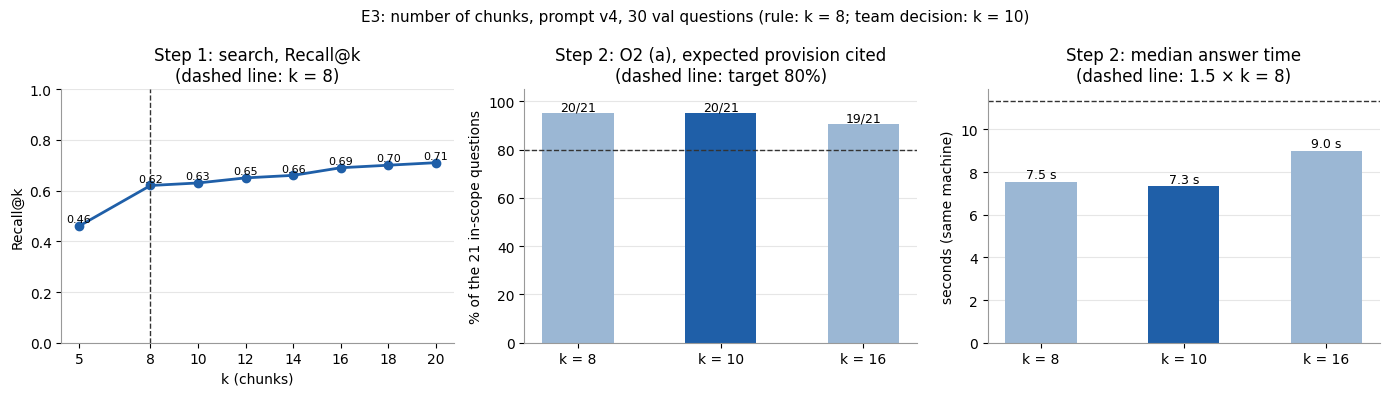

In [27]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
INK, GRID, BAR, CHOSEN_C = "#333333", "#e6e6e6", "#9bb7d4", "#1f5fa8"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#999999"})
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ax = axes[0]
ax.plot(recall["k"], recall["Recall@k"], marker="o", color=CHOSEN_C, linewidth=2)
for k, v in zip(recall["k"], recall["Recall@k"]):
    ax.text(k, v + 0.015, f"{v:.2f}", ha="center", fontsize=8)
ax.axvline(8, color=INK, linestyle="--", linewidth=1); ax.set_ylim(0, 1); ax.set_xticks(recall["k"])
ax.set_xlabel("k (chunks)"); ax.set_ylabel("Recall@k"); ax.set_title("Step 1: search, Recall@k\n(dashed line: k = 8)")
names = [f"k = {k}" for k in K_LIST]
colours = [CHOSEN_C if k == FINAL_K else BAR for k in K_LIST]
ax = axes[1]
share = [100 * numbers[k]["O2 (a) cited"] / numbers[k]["of"] for k in K_LIST]
ax.bar(names, share, color=colours, width=0.5); ax.axhline(80, color=INK, linestyle="--", linewidth=1)
for i, k in enumerate(K_LIST):
    ax.text(i, share[i] + 1, f"{numbers[k]['O2 (a) cited']}/{numbers[k]['of']}", ha="center", fontsize=9)
ax.set_ylim(0, 105); ax.set_ylabel("% of the 21 in-scope questions"); ax.set_title("Step 2: O2 (a), expected provision cited\n(dashed line: target 80%)")
ax = axes[2]
med = [numbers[k]["median time (s)"] for k in K_LIST]
ax.bar(names, med, color=colours, width=0.5); ax.axhline(TIME_FACTOR * numbers[8]["median time (s)"], color=INK, linestyle="--", linewidth=1)
for i, m in enumerate(med):
    ax.text(i, m * 1.02, f"{m:.1f} s", ha="center", fontsize=9)
ax.set_ylabel("seconds (same machine)"); ax.set_title(f"Step 2: median answer time\n(dashed line: {TIME_FACTOR} × k = 8)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
fig.suptitle(f"E3: number of chunks, prompt v4, 30 val questions (rule: k = {CHOSEN}; team decision: k = {FINAL_K})", fontsize=11)
fig.tight_layout()
PDF_FILE = "../docs/eval/e3-top-k-results.pdf"
with PdfPages(PDF_FILE) as pdf:
    pdf.savefig(fig)
recall.to_csv("../docs/eval/answers/e3-recall-at-k.csv", index=False)
ranks_table.to_csv("../docs/eval/answers/e3-gold-ranks.csv", index=False)
result.to_csv("../docs/eval/answers/e3-top-k-results.csv")
print("Saved", PDF_FILE, "and the tables in docs/eval/answers/")
plt.show()

## Results against the charter targets

In [28]:
def meets(value, ok):
    return f"{value} " + ("✓" if ok else "✗")
rows = []
for k in sorted({8, FINAL_K}):
    n = numbers[k]
    rows.append({"k": k,
                 "O2 (a) expected provision (≥ 80%)": meets(pct(n["O2 (a) cited"], n["of"]), n["O2 (a) cited"] / n["of"] >= 0.8),
                 "O2 (c) reference + date (100%)": meets(n["O2 (c), all substantive answers"], n["O2 (c), all substantive answers"].endswith("100%")),
                 "O2 (d) wrong dates (≤ 1)": meets(n["O2 (d) wrong dates"], n["O2 (d) wrong dates"] <= 1),
                 "O4 (a) verdict sentences (0)": meets(n["verdict"], n["verdict"] == 0),
                 "O1 median CPU time (≤ 60 s)": "measured later with src/answer_time.py"})
charter_table = pd.DataFrame(rows).set_index("k")
charter_table

,O2 (a) expected provision (≥ 80%),O2 (c) reference + date (100%),O2 (d) wrong dates (≤ 1),O4 (a) verdict sentences (0),O1 median CPU time (≤ 60 s)
k,,,,,
8,20/21 = 95% ✓,27/27 = 100% ✓,1 ✓,2 ✗,measured later with src/answer_time.py
10,20/21 = 95% ✓,28/28 = 100% ✓,0 ✓,0 ✓,measured later with src/answer_time.py


**Comment:** with k = 10 every target measured here is met; with k = 8, O4 (a) is not (2 verdict sentences). O1 (CPU time) is measured later.

**Rows for the technical summary** (section 3 of the template), with the W&B links.

## 14. W&B
One run for Part 1, one for the ranks, one per k (group `E3-E4-search-and-k`).

In [29]:
URLS = {}
if LOG_TO_WANDB:
    import wandb
    wandb.login()
    try:
        settings = wandb.Settings(x_disable_meta=True, x_disable_stats=True, save_code=False)
    except Exception:
        settings = wandb.Settings(save_code=False)
    GROUP = "E3-E4-search-and-k"
    common = {"eval_set": EVAL_SET, "split": SPLIT, "code_commit": CODE_COMMIT, "source": SOURCE, "rag_yaml": CONFIG, "device": DEVICE}
    run = wandb.init(project="eliza-rag", name="E4-search-settings", group=GROUP, job_type="retrieval", tags=["sprint-3", "E4", SPLIT], settings=settings,
                     config={**common, "run_jury": RUN_JURY, "jury": JURY, "embedding_models": EMBEDDING_MODELS, "dense_weights": DENSE_WEIGHTS,
                             "chosen_model": BEST_MODEL, "chosen_weight": BEST_WEIGHT, "bm25_remove": BM25_LIST, "legal_words_kept": KEEP_LEGAL, "remove_before_embedding": REMOVE_BEFORE_EMBEDDING})
    wandb.log({**{k: v for k, v in score(chosen_search).items()}, "jury": wandb.Table(dataframe=jury.astype(str)),
               "bm25_word_lists": wandb.Table(dataframe=bm25_table.reset_index().astype(str)), "hybrid_word_lists": wandb.Table(dataframe=hybrid_words.astype(str)), "models_and_weights": wandb.Table(dataframe=searches.astype(str)),
               "recall_at_k_per_model": wandb.Table(dataframe=at_k.astype(str)), "before_embedding": wandb.Table(dataframe=before_table.reset_index().astype(str)),
               "chosen": wandb.Table(dataframe=chosen.reset_index().astype(str))})
    URLS["E4-search-settings"] = run.url; run.finish()
    common.update({"prompt_ref": PROMPT_REF, "prompt_commit": COMMIT, "prompt_id": PROMPT_ID, "model": A["model"], "ollama": "0.40.15",
                   "num_predict": A["num_predict"], "temperature": A["temperature"], "seed": A["seed"], "num_ctx": NUM_CTX, "rule_k": CHOSEN, "final_k": FINAL_K})
    run = wandb.init(project="eliza-rag", name="E3-step1-ranks", group=GROUP, job_type="retrieval", tags=["sprint-3", "E3", SPLIT], settings=settings,
                     config={**common, "k_tried": K_LIST, "decision_rule": f"+1 question, no more verdicts, median time <= {TIME_FACTOR} x k = 8, fits {NUM_CTX}"})
    wandb.log({**{f"Recall@{k}": float(v) for k, v in zip(recall["k"], recall["Recall@k"])}, "recall": wandb.Table(dataframe=recall.astype(str)),
               "gold_ranks": wandb.Table(dataframe=ranks_table.astype(str)), "prompt_size": wandb.Table(dataframe=size.astype(str)),
               "decision": wandb.Table(dataframe=decision.reset_index().astype(str)), "charts/e3": wandb.Image(fig)})
    URLS["E3-step1-ranks"] = run.url; run.finish()
    for k in K_LIST:
        n = numbers[k]
        run = wandb.init(project="eliza-rag", name=f"E3-k{k}" + ("-reference" if k == 8 else ""), group=GROUP, job_type="answers",
                         tags=["sprint-3", "E3", SPLIT], settings=settings, config={**common, "top_k": k})
        wandb.log({"o2a_cited": n["O2 (a) cited"], "o2a_share": n["O2 (a) cited"] / n["of"], "verdict": n["verdict"], "fixed_sentence": n["fixed sentence"],
                   "median_seconds": n["median time (s)"], "max_prompt_tokens": n["max prompt tokens"],
                   "answers": wandb.Table(dataframe=pd.DataFrame(answers[k].values()).drop(columns=["chunks"]).astype(str))})
        art = wandb.Artifact(f"e3-k{k}-{SPLIT}", type="dataset"); art.add_file(OUT[k]); run.log_artifact(art)
        URLS[f"E3-k{k}"] = run.url; run.finish()
print(URLS)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: gozdenur104 (gozdenur104-metu-middle-east-technical-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Capped recall@8,▁
MRR,▁
Precision@8,▁
Recall@8,▁
Capped recall@8,0.64
MRR,0.62
Precision@8,0.19
Recall@8,0.62


Recall@10,▁
Recall@12,▁
Recall@14,▁
Recall@16,▁
Recall@18,▁
Recall@20,▁
Recall@5,▁
Recall@8,▁
Recall@10,0.63
Recall@12,0.65
Recall@14,0.66


fixed_sentence,▁
max_prompt_tokens,▁
median_seconds,▁
o2a_cited,▁
o2a_share,▁
verdict,▁
fixed_sentence,3
max_prompt_tokens,2520
median_seconds,7.55
o2a_cited,20
o2a_share,0.95238


fixed_sentence,▁
max_prompt_tokens,▁
median_seconds,▁
o2a_cited,▁
o2a_share,▁
verdict,▁
fixed_sentence,2
max_prompt_tokens,2802
median_seconds,7.35
o2a_cited,20
o2a_share,0.95238


fixed_sentence,▁
max_prompt_tokens,▁
median_seconds,▁
o2a_cited,▁
o2a_share,▁
verdict,▁
fixed_sentence,3
max_prompt_tokens,3325
median_seconds,9
o2a_cited,19
o2a_share,0.90476


{'E4-search-settings': 'https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/fzohutgx', 'E3-step1-ranks': 'https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/qx2rgzus', 'E3-k8': 'https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/zxrho7cs', 'E3-k10': 'https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/ih4q72rv', 'E3-k16': 'https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/5ce22zts'}


In [30]:
link = lambda name: f"[{URLS[name].rsplit('/', 1)[-1]}]({URLS[name]})" if name in URLS else "not logged"
rec_k = lambda k: score(chosen_search, k)[f"Recall@{k}"]
summary_rows = [
    "| Experiment | Best run (W&B) | Recall@8 | O2 (a) | Repeats (n) |",
    "|---|---|---|---|---|",
    f"| E4 Search settings ({short_name(BEST_MODEL)}, dense weight {BEST_WEIGHT}, BM25 {BM25_LIST}{', legal words kept' if KEEP_LEGAL else ''}) | {link('E4-search-settings')} | {rec_k(8)} | null | 1 |",
    f"| E3 Number of chunks (k = {FINAL_K}, prompt v4) | {link(f'E3-k{FINAL_K}')} | {rec_k(8)} (Recall@{FINAL_K} {rec_k(FINAL_K)}) | {pct(numbers[FINAL_K]['O2 (a) cited'], numbers[FINAL_K]['of'])} | 1 |",
]
print("\n".join(summary_rows))
print("\nnull: E4 compares search settings only, so it gives no answers (no O2 (a)).")

| Experiment | Best run (W&B) | Recall@8 | O2 (a) | Repeats (n) |
|---|---|---|---|---|
| E4 Search settings (bge-m3, dense weight 0.8, BM25 stopwords + jury, legal words kept) | [fzohutgx](https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/fzohutgx) | 0.62 | null | 1 |
| E3 Number of chunks (k = 10, prompt v4) | [ih4q72rv](https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/ih4q72rv) | 0.62 (Recall@10 0.63) | 20/21 = 95% | 1 |

null: E4 compares search settings only, so it gives no answers (no O2 (a)).


## 15. For the experiment cards and Jira

In [31]:
card = pd.DataFrame([
    {"": "E4 · question", "value": "Is the Sprint 2 search (bge-m3, dense weight 0.8, BM25 without stopwords + jury words) still the best on the current val questions, also at more than 8 chunks? (The search does not use the prompt.)"},
    {"": "E4 · baseline", "value": f"Sprint 2 search, Recall@8 = 0.59 (E1); now {score(chosen_search)['Recall@8']} with corrected gold provisions"},
    {"": "E4 · parameter space", "value": f"{len(EMBEDDING_MODELS)} embedding models x {len(DENSE_WEIGHTS)} dense weights; {len(REMOVE)} BM25 word lists on BM25 alone; {len(variants)} BM25 versions inside the hybrid search (with and without the legal words); {len(before)} versions before embedding"},
    {"": "E4 · search method", "value": "grid search on the 29 val questions with gold provisions; Recall@8, then MRR (Sprint 2 rules)"},
    {"": "E4 · result", "value": f"{short_name(BEST_MODEL)}, weight {BEST_WEIGHT}, BM25 '{BM25_LIST}', before embedding '{REMOVE_BEFORE_EMBEDDING}' (same as Sprint 2: {bool(chosen['same'].all())})"},
    {"": "E3 · question", "value": "With prompt v4 and the chosen search, is 8 still the best number of chunks?"},
    {"": "E3 · baseline", "value": f"k = 8 with prompt v4 (E2): O2 (a) {numbers[8]['O2 (a) cited']}/{numbers[8]['of']}"},
    {"": "E3 · parameter space", "value": f"k = 5 to {K_MAX} for the ranks; answered: k = {K_LIST}"},
    {"": "E3 · search method", "value": "ranks of the gold provisions -> every k that brings a missing one in -> answers -> reading -> four rules"},
    {"": "E3 · result", "value": f"rule: k = {CHOSEN}; team decision: k = {FINAL_K}; " + "; ".join(f"k = {k}: O2 (a) {numbers[k]['O2 (a) cited']}/{numbers[k]['of']}, verdicts {numbers[k]['verdict']}, median {numbers[k]['median time (s)']} s" for k in K_LIST)},
    {"": "W&B runs", "value": ", ".join(f"{n}: {u}" for n, u in URLS.items()) or "not logged"},
]).set_index("")
card

,value
,
E4 · question,"Is the Sprint 2 search (bge-m3, dense weight 0.8, BM25 without stopwords + jury words) still the best on the current val questions, also at more than 8 chunks? (The search does not use the prompt.)"
E4 · baseline,"Sprint 2 search, Recall@8 = 0.59 (E1); now 0.62 with corrected gold provisions"
E4 · parameter space,5 embedding models x 6 dense weights; 6 BM25 word lists on BM25 alone; 11 BM25 versions inside the hybrid search (with and without the legal words); 6 versions before embedding
E4 · search method,"grid search on the 29 val questions with gold provisions; Recall@8, then MRR (Sprint 2 rules)"
E4 · result,"bge-m3, weight 0.8, BM25 'stopwords + jury', before embedding 'none' (same as Sprint 2: False)"
E3 · question,"With prompt v4 and the chosen search, is 8 still the best number of chunks?"
E3 · baseline,k = 8 with prompt v4 (E2): O2 (a) 20/21
E3 · parameter space,"k = 5 to 20 for the ranks; answered: k = [8, 10, 16]"
E3 · search method,ranks of the gold provisions -> every k that brings a missing one in -> answers -> reading -> four rules


## 16. Download

In [32]:
for name, t in {"e4-bm25-word-lists": bm25_table, "e4-models-and-weights": searches, "e4-recall-at-k-per-model": at_k,
                "e4-before-embedding": before_table, "e4-hybrid-word-lists": hybrid_words, "e4-chosen": chosen, "e3-e4-card": card}.items():
    t.to_csv(f"../docs/eval/answers/{name}.csv")
print("Prompt commit:", COMMIT[:7], "| code commit:", CODE_COMMIT[:7], "| search:", short_name(BEST_MODEL), BEST_WEIGHT, "| k tried:", K_LIST, "| rule k:", CHOSEN, "| final k:", FINAL_K)
if "google.colab" in sys.modules:
    import glob, zipfile
    from google.colab import files
    with zipfile.ZipFile("/content/search-and-k-files.zip", "w") as z:
        for p in sorted(glob.glob("../docs/eval/answers/e3-*") + glob.glob("../docs/eval/answers/e4-*") + [PDF_FILE]):
            z.write(p, p.replace("../", ""))
    files.download("/content/search-and-k-files.zip")

Prompt commit: b5140a0 | code commit: 033de8e | search: bge-m3 0.8 | k tried: [8, 10, 16] | rule k: 8 | final k: 10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>